In [21]:
# imports
from pathlib import Path
import zipfile
import pandas as pd

In [22]:
# verifying dataset files
zip_path = "../datasets/bank_marketing.zip"

with zipfile.ZipFile(zip_path) as z:
    print(z.namelist())

['bank-additional-full.csv', 'bank-additional-names.txt', 'bank-full.csv', 'bank-names.txt']


In [23]:
# reading documentation
with zipfile.ZipFile(zip_path) as z:
    with z.open("bank-additional-names.txt") as f:
        print(f.read().decode())

Citation Request:
  This dataset is publicly available for research. The details are described in [Moro et al., 2014]. 
  Please include this citation if you plan to use this database:

  [Moro et al., 2014] S. Moro, P. Cortez and P. Rita. A Data-Driven Approach to Predict the Success of Bank Telemarketing. Decision Support Systems, In press, http://dx.doi.org/10.1016/j.dss.2014.03.001

  Available at: [pdf] http://dx.doi.org/10.1016/j.dss.2014.03.001
                [bib] http://www3.dsi.uminho.pt/pcortez/bib/2014-dss.txt

1. Title: Bank Marketing (with social/economic context)

2. Sources
   Created by: Sérgio Moro (ISCTE-IUL), Paulo Cortez (Univ. Minho) and Paulo Rita (ISCTE-IUL) @ 2014
   
3. Past Usage:

  The full dataset (bank-additional-full.csv) was described and analyzed in:

  S. Moro, P. Cortez and P. Rita. A Data-Driven Approach to Predict the Success of Bank Telemarketing. Decision Support Systems (2014), doi:10.1016/j.dss.2014.03.001.
 
4. Relevant Information:

   This 

In [24]:
# loading dataset
with zipfile.ZipFile(zip_path) as z:
    with z.open("bank-additional-full.csv") as f:
        df = pd.read_csv(f, sep=";")

print(df.shape)
df.head()

(41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [25]:
# fixing pdays 
df["previously_contacted"] = (df["pdays"] != 999).astype(int)
df["pdays"] = df["pdays"].replace(999, float("nan"))

df["previously_contacted"].value_counts()

previously_contacted
0    39673
1     1515
Name: count, dtype: int64

In [26]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,41188.0,40.024060,10.421250,17.000,32.000,38.000,47.000,98.000
duration,41188.0,258.285010,259.279249,0.000,102.000,180.000,319.000,4918.000
campaign,41188.0,2.567593,2.770014,1.000,1.000,2.000,3.000,56.000
pdays,1515.0,6.014521,3.824906,0.000,3.000,6.000,7.000,27.000
previous,41188.0,0.172963,0.494901,0.000,0.000,0.000,0.000,7.000
emp.var.rate,41188.0,0.081886,1.570960,-3.400,-1.800,1.100,1.400,1.400
cons.price.idx,41188.0,93.575664,0.578840,92.201,93.075,93.749,93.994,94.767
cons.conf.idx,41188.0,-40.502600,4.628198,-50.800,-42.700,-41.800,-36.400,-26.900
euribor3m,41188.0,3.621291,1.734447,0.634,1.344,4.857,4.961,5.045
nr.employed,41188.0,5167.035911,72.251528,4963.600,5099.100,5191.000,5228.100,5228.100


In [28]:
df.isna().sum()

age                         0
job                         0
marital                     0
education                   0
default                     0
housing                     0
loan                        0
contact                     0
month                       0
day_of_week                 0
duration                    0
campaign                    0
pdays                   39673
previous                    0
poutcome                    0
emp.var.rate                0
cons.price.idx              0
cons.conf.idx               0
euribor3m                   0
nr.employed                 0
y                           0
previously_contacted        0
dtype: int64

In [ ]:
# checking missing values ("unknown")
unknown_count = (df == "unknown").sum()
print("Missing values:\n",unknown_count)


Missing values:
 age                        0
job                      330
marital                   80
education               1731
default                 8597
housing                  990
loan                     990
contact                    0
month                      0
day_of_week                0
duration                   0
campaign                   0
pdays                      0
previous                   0
poutcome                   0
emp.var.rate               0
cons.price.idx             0
cons.conf.idx              0
euribor3m                  0
nr.employed                0
y                          0
previously_contacted       0
dtype: int64


In [13]:
# check duplicates
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 12


In [27]:
# target distribution
df["y"].value_counts(normalize=True)

y
no     0.887346
yes    0.112654
Name: proportion, dtype: float64

<Axes: title={'center': 'Target Distribution'}, xlabel='y'>

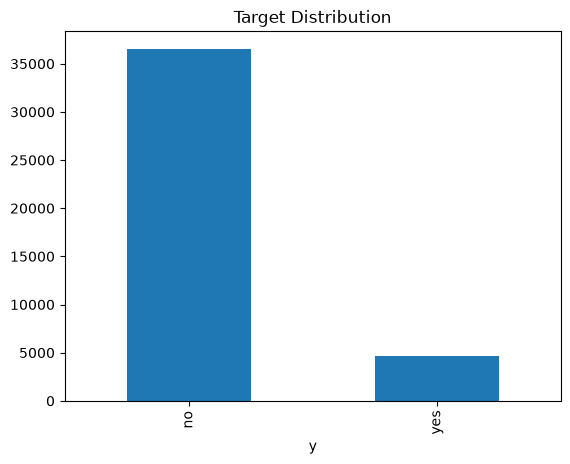

In [ ]:
# first visualization
df["y"].value_counts().plot(kind="bar", title="Target Distribution")